Weights:
      Equal (start)  Max Sharpe
CBRS            0.2         1.0
META            0.2         0.0
MRVL            0.2         0.0
NVDA            0.2         0.0
TSLA            0.2         0.0

Train days: 2026-11-17 to 2026-11-23 | Test days: 2026-11-24 to 2026-11-25

Equal 0.2  | TRAIN Sharpe -12.37 | TEST Sharpe  +4.86 | TEST return +2.21%
Max Sharpe | TRAIN Sharpe  -6.30 | TEST Sharpe  -2.40 | TEST return -2.40%


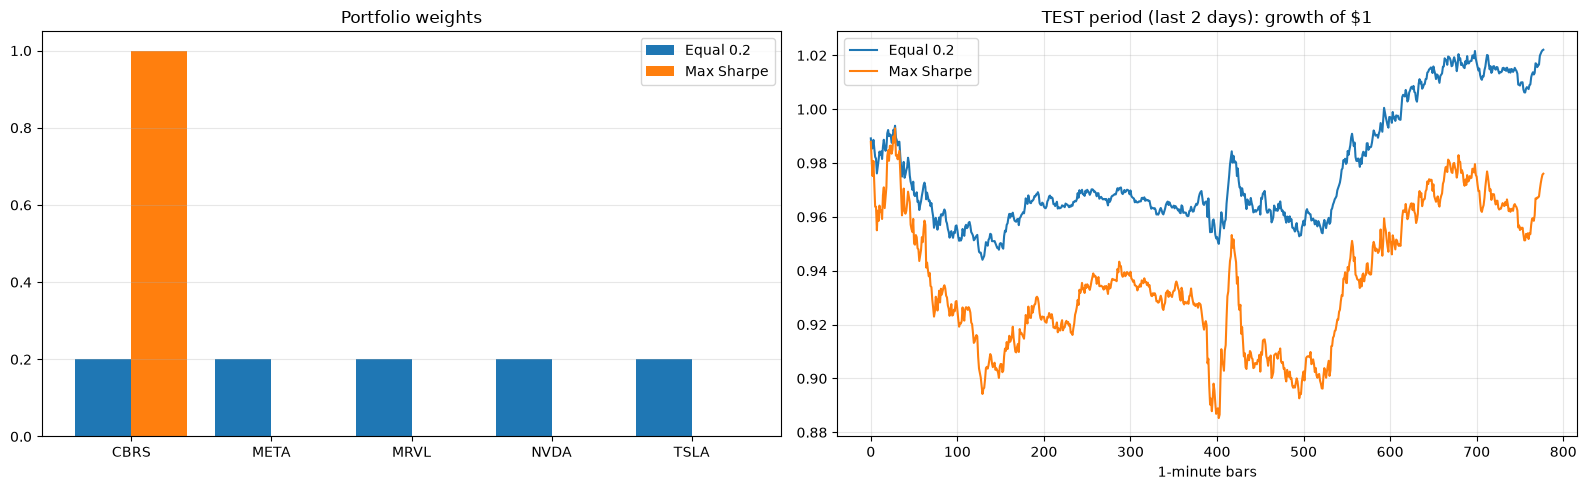

In [8]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

tickers = ["MRVL", "NVDA", "TSLA", "CBRS", "META"]

# 1-minute data, last 7 days (yfinance max for 1m)
close = yf.download(tickers, period="7d", interval="1m", progress=False)["Close"].dropna()
close.index = close.index.tz_convert("America/New_York")

# Returns WITHIN each day (skip the overnight gap between days)
rets = close.groupby(close.index.date).pct_change().dropna()
names = list(rets.columns)
bars_per_year = 390 * 252   # 1-minute bars in a trading year

def stats(w, r):
    port = r.values @ w
    ann_ret = port.mean() * bars_per_year
    ann_vol = port.std() * np.sqrt(bars_per_year)
    return ann_ret, ann_vol, ann_ret / ann_vol

def max_sharpe(r):
    n = r.shape[1]
    res = minimize(lambda w: -stats(w, r)[2], np.full(n, 1 / n), method="SLSQP",
                   bounds=[(0, 1)] * n,                                     # long only, 0-100% each
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})  # weights add to 100%
    return res.x

# Split: first 5 days = optimize, last 2 days = test
days = sorted(set(rets.index.date))
train = rets[[d in days[:-2] for d in rets.index.date]]
test = rets[[d in days[-2:] for d in rets.index.date]]

w_equal = np.full(len(names), 0.2)
w_opt = max_sharpe(train)

print("Weights:")
print(pd.DataFrame({"Equal (start)": w_equal, "Max Sharpe": w_opt.round(3)}, index=names))

print(f"\nTrain days: {days[0]} to {days[-3]} | Test days: {days[-2]} to {days[-1]}\n")
for label, w in [("Equal 0.2", w_equal), ("Max Sharpe", w_opt)]:
    tr, te = stats(w, train), stats(w, test)
    print(f"{label:10} | TRAIN Sharpe {tr[2]:+6.2f} | TEST Sharpe {te[2]:+6.2f} "
          f"| TEST return {((1 + test.values @ w).prod() - 1):+.2%}")

# Plots: weights, and test-period performance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(names))
ax1.bar(x - 0.2, w_equal, 0.4, label="Equal 0.2")
ax1.bar(x + 0.2, w_opt, 0.4, label="Max Sharpe")
ax1.set_xticks(x)
ax1.set_xticklabels(names)
ax1.set_title("Portfolio weights")
ax1.legend()
ax1.grid(True, axis="y", alpha=0.3)

for label, w in [("Equal 0.2", w_equal), ("Max Sharpe", w_opt)]:
    ax2.plot(range(len(test)), (1 + test.values @ w).cumprod(), label=label)
ax2.set_title("TEST period (last 2 days): growth of $1")
ax2.set_xlabel("1-minute bars")
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
def optimize(r, objective, cap=1.0):
    n = r.shape[1]
    res = minimize(objective, np.full(n, 1 / n), args=(r,), method="SLSQP",
                   bounds=[(0, cap)] * n,
                   constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return res.x

neg_sharpe = lambda w, r: -stats(w, r)[2]
variance = lambda w, r: (r.values @ w).std() * np.sqrt(bars_per_year)

portfolios = {
    "Equal 0.2": np.full(len(names), 0.2),
    "Max Sharpe (no cap)": optimize(train, neg_sharpe),
    "Max Sharpe (cap 40%)": optimize(train, neg_sharpe, cap=0.4),
    "Min variance": optimize(train, variance),
}

print(pd.DataFrame(portfolios, index=names).round(2), "\n")
for label, w in portfolios.items():
    te = stats(w, test)
    print(f"{label:22} | TEST Sharpe {te[2]:+6.2f} | TEST return {((1 + test.values @ w).prod() - 1):+.2%} "
          f"| TEST vol {te[1]:.0%}")

      Equal 0.2  Max Sharpe (no cap)  Max Sharpe (cap 40%)  Min variance
CBRS        0.2                  1.0                   0.4          0.00
META        0.2                  0.0                   0.2          0.72
MRVL        0.2                  0.0                   0.0          0.00
NVDA        0.2                  0.0                   0.0          0.00
TSLA        0.2                  0.0                   0.4          0.28 

Equal 0.2              | TEST Sharpe  +4.86 | TEST return +2.21% | TEST vol 61%
Max Sharpe (no cap)    | TEST Sharpe  -2.40 | TEST return -2.40% | TEST vol 105%
Max Sharpe (cap 40%)   | TEST Sharpe  +4.66 | TEST return +2.12% | TEST vol 61%
Min variance           | TEST Sharpe +18.18 | TEST return +5.95% | TEST vol 41%


- Fixed min-variance: 72% META / 28% TSLA, dropped the correlated chip names; lowest test vol (41% vs 61% equal) = the reliable part
- Its +5.95% / Sharpe 18 return is luck (2 test days, min-var ignores returns)
- Lesson: vol/correlation estimates carry forward, return estimates don't -> min-var/equal weight > max Sharpe out of sample

- Swapped GOOGL->CBRS: uncapped max Sharpe moved 100% to CBRS (new most volatile) -> -2.40% test vs equal +2.21%
- Cap 40% fixes it: +2.12%, vol 61% ~ equal weight
- Optimizer bug: 1-min variance too small for SLSQP tolerance -> scale objective (annualize) or it never moves

- Max-Sharpe on 1-min data (5 train days, 2 test days): 100% MRVL; equal 0.2 won on test (+3.22% vs +0.59%). With negative train returns, max Sharpe rewards the MOST volatile stock -> cap weights or use min-variance